In [ ]:
#REDACTED_GOOGLE_API_KEY
#REDACTED_OPENAI_KEY

In [1]:
!pip install google-api-python-client
!pip install youtube-transcript-api openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.2/485.2 kB 10.7 MB/s eta 0:00:00


In [2]:
from googleapiclient.discovery import build
import pandas as pd

# 🔑 Replace with your API key
API_KEY = "REDACTED_GOOGLE_API_KEY"

youtube = build("youtube", "v3", developerKey=API_KEY)

QUERY = "Full Python Course"
MAX_VIDEOS = 20
MAX_COMMENTS = 100

videos_data = []
comments_data = []

# 🔍 Search videos
search_response = youtube.search().list(
    q=QUERY,
    part="id,snippet",
    type="video",
    maxResults=MAX_VIDEOS
).execute()

for item in search_response["items"]:
    video_id = item["id"]["videoId"]
    title = item["snippet"]["title"]
    channel = item["snippet"]["channelTitle"]

    # 📊 Video metadata
    video_response = youtube.videos().list(
        part="statistics,contentDetails,snippet",
        id=video_id
    ).execute()

    video_info = video_response["items"][0]
    stats = video_info["statistics"]
    details = video_info["contentDetails"]
    snippet = video_info["snippet"]

    videos_data.append({
    "video_id": video_id,
    "video_title": title,
    "description": snippet.get("description", ""),
    "channel_name": channel,
    "views": int(stats.get("viewCount", 0)),
    "likes": int(stats.get("likeCount", 0)),
    "duration": details["duration"],
    "publish_date": snippet["publishedAt"],
    "video_url": f"https://www.youtube.com/watch?v={video_id}"
})

    # 💬 Comments
    try:
        comment_response = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=MAX_COMMENTS,
            textFormat="plainText"
        ).execute()

        for c in comment_response.get("items", []):
            comment = c["snippet"]["topLevelComment"]["snippet"]
            comments_data.append({
                "video_id": video_id,
                "comment_id": c["id"],
                "comment_text": comment["textDisplay"],
                "timestamp": comment["publishedAt"]
            })

    except:
        print(f"Comments disabled for video {video_id}")

# 💾 Save data
videos_df = pd.DataFrame(videos_data)
comments_df = pd.DataFrame(comments_data)

videos_df.to_csv("youtube_videos.csv", index=False)
comments_df.to_csv("youtube_comments.csv", index=False)

print("Phase 1 completed")
print("Videos collected:", len(videos_df))
print("Comments collected:", len(comments_df))


Comments disabled for video YvYKcGAfJvs
Phase 1 completed
Videos collected: 25
Comments collected: 2210


In [3]:
import pandas as pd
import re

# Load raw comments
comments_df = pd.read_csv("youtube_comments.csv")

# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)           # remove URLs
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # remove special chars
    text = re.sub(r"\s+", " ", text).strip()      # normalize spaces
    return text

comments_df["clean_comment"] = comments_df["comment_text"].astype(str).apply(clean_text)
comments_df["comment_length"] = comments_df["clean_comment"].apply(lambda x: len(x.split()))

# Save cleaned comments
comments_df.to_csv("youtube_comments_cleaned.csv", index=False)

print("Phase 2 completed")
print("Total cleaned comments:", len(comments_df))
comments_df.head()


Phase 2 completed
Total cleaned comments: 2210


,video_id,comment_id,comment_text,timestamp,clean_comment,comment_length
0,K5KVEU3aaeQ,Ugyz70nN7eD2hYKS4Rt4AaABAg,🔥Want to master Python? Get my Python mastery ...,2025-02-12T18:50:18Z,want to master python get my python mastery co...,26
1,K5KVEU3aaeQ,UgzYUuTa-c9OaTJzyyN4AaABAg,I am ten years old but it is very easy to learn,2026-02-27T15:00:19Z,i am ten years old but it is very easy to learn,12
2,K5KVEU3aaeQ,Ugz8H_nBB24I_z-LkjJ4AaABAg,I'm starting to take my tech journey seriously...,2026-02-27T11:24:18Z,i m starting to take my tech journey seriously...,30
3,K5KVEU3aaeQ,Ugz6Fx2NOoeKBIjYYJZ4AaABAg,"I'm a python beginner, great vid!!!",2026-02-27T11:23:46Z,i m a python beginner great vid,7
4,K5KVEU3aaeQ,UgzA7SZGM14fS5xWwjp4AaABAg,"I hate to say this so early on, but I am unabl...",2026-02-26T22:55:45Z,i hate to say this so early on but i am unable...,52


In [4]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer


In [5]:
comments_df = pd.read_csv("/content/youtube_comments_cleaned.csv")

# Sanity check
assert "clean_comment" in comments_df.columns
semantic_query = "Complete Python programming tutorial explaining concepts and problem solving"
model = SentenceTransformer("intfloat/e5-base-v2")
comments = comments_df["clean_comment"].fillna("").tolist()

comment_embeddings = model.encode(
    ["passage: " + c for c in comments],
    normalize_embeddings=True,
    batch_size=32,
    show_progress_bar=True
)
query_embedding = model.encode(
    ["query: " + semantic_query],
    normalize_embeddings=True
)
relevance_scores = np.dot(
    comment_embeddings,
    query_embedding.T
).squeeze()


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/70 [00:00<?, ?it/s]

In [6]:
comments_df["relevance_score"] = relevance_scores
comments_df = comments_df.sort_values(
    by="relevance_score",
    ascending=False
)
comments_df.to_csv(
    "phase3_comments_relevance.csv",
    index=False
)


In [7]:
phase3_df = pd.read_csv("phase3_comments_relevance.csv")
TOP_K = 1000  # justified as top-K semantic filtering

relevant_df = (
    phase3_df
    .sort_values("relevance_score", ascending=False)
    .head(TOP_K)
    .copy()
)

print("Selected relevant comments:", len(relevant_df))


Selected relevant comments: 1000


In [8]:
from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    truncation=True,
    max_length=512
)

print("Sentiment model loaded successfully")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Sentiment model loaded successfully


In [9]:
sentiment_model("This course is absolutely amazing!")


[{'label': 'positive', 'score': 0.9776747822761536}]

In [10]:
def sentiment_score(text):
    result = sentiment_model(text)[0]

    label = result["label"].lower()
    score = result["score"]

    if label == "positive":
        return score
    elif label == "negative":
        return -score
    else:
        return 0.0


In [11]:
print(sentiment_score("This course is amazing"))
print(sentiment_score("This tutorial is terrible"))
print(sentiment_score("This is a Python video"))


0.9751406908035278
-0.9413253664970398
0.0


In [12]:
# Ensure clean_comment is string and not null
relevant_df = relevant_df.dropna(subset=["clean_comment"])
relevant_df["clean_comment"] = relevant_df["clean_comment"].astype(str)

print("Remaining relevant comments:", len(relevant_df))


Remaining relevant comments: 963


In [13]:
def safe_sentiment_score(text):
    try:
        return sentiment_score(text)
    except:
        return 0.0   # neutral fallback


In [14]:
relevant_df["sentiment_score"] = relevant_df["clean_comment"].apply(safe_sentiment_score)

relevant_df[["clean_comment", "relevance_score", "sentiment_score"]].head()


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,clean_comment,relevance_score,sentiment_score
0,does this course cover whole python concept,0.850329,0.000000
1,the tutorial is brilliant as usual my friend s...,0.845419,0.982108
2,your are an incredible instructor man i was wa...,0.844283,0.980628
3,i think this is the best python tutorial on yo...,0.842398,0.982321
4,dear friends i ve spent a year creating this f...,0.840681,0.851784


In [15]:
relevant_df["sentiment_score"].describe()


,sentiment_score
count,963.000000
mean,0.223771
std,0.535823
min,-0.945177
25%,0.000000
50%,0.000000
75%,0.849808
max,0.990728


In [16]:
relevant_df = relevant_df.copy()
relevant_df.loc[:, "sentiment_score"] = relevant_df["clean_comment"].apply(safe_sentiment_score)


In [17]:
# Finalize Phase 4 output
relevant_df.to_csv(
    "phase4_relevant_comments_sentiment.csv",
    index=False
)

print("✅ Phase 4 finalized and saved successfully")
print("Rows saved:", len(relevant_df))


✅ Phase 4 finalized and saved successfully
Rows saved: 963


PHASE 5 – Emotion-Weighted Engagement Formulation (CORE NOVELTY)

In [18]:
import numpy as np
import pandas as pd
relevant_df = pd.read_csv("/content/phase4_relevant_comments_sentiment.csv")

relevant_df.head()
relevant_df["emotion_weighted_score"] = (
    relevant_df["relevance_score"] * relevant_df["sentiment_score"]
)


In [19]:
relevant_df["emotion_weighted_score"] = (
    relevant_df["relevance_score"] * relevant_df["sentiment_score"]
)


In [20]:
video_emotion_df = (
    relevant_df
    .groupby("video_id")
    .agg(
        emotional_engagement=("emotion_weighted_score", "mean"),
        emotional_variance=("emotion_weighted_score", "var"),
        relevant_comment_count=("emotion_weighted_score", "count")
    )
    .reset_index()
)


In [21]:
video_emotion_df.head()


,video_id,emotional_engagement,emotional_variance,relevant_comment_count
0,4M87qBgpafk,0.268597,0.254983,37
1,80yIVH2aOy0,-0.083809,0.072728,27
2,8DvywoWv6fI,0.156019,0.187836,38
3,AQJbHAeUhzM,0.015480,0.147435,41
4,H2EJuAcrZYU,0.213939,0.230399,51


In [22]:
video_emotion_df.to_csv("phase5_video_emotional_engagement.csv", index=False)
print("✅ Phase 5 completed successfully")


✅ Phase 5 completed successfully


PHASE 6: FINAL ENGAGEMENT SCORE & VIDEO RANKING

In [23]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Load Phase 5 data
phase5 = pd.read_csv("/content/phase5_video_emotional_engagement.csv")

# Load video metadata
videos = pd.read_csv("youtube_videos.csv")

# Merge on video_id
df = phase5.merge(videos, on="video_id", how="inner")

# Select columns for normalization
scaler = MinMaxScaler()

df[["likes_norm", "comment_count_norm"]] = scaler.fit_transform(
    df[["likes", "relevant_comment_count"]]
)

# Compute Final Engagement Score
df["final_engagement_score"] = (
    0.4 * df["emotional_engagement"] +
    0.2 * (1 - df["emotional_variance"]) +
    0.2 * df["likes_norm"] +
    0.2 * df["comment_count_norm"]
)

# Rank videos
df["rank"] = df["final_engagement_score"].rank(
    ascending=False, method="dense"
)

# Sort by rank
df = df.sort_values("rank")

# Save Phase 6 output
df[["video_id", "final_engagement_score", "rank"]].to_csv(
    "phase6_final_video_ranking.csv", index=False
)

df.head()
df.to_csv("phase6_full.csv", index=False)


PHASE 7 – Public Transcript Only Pipeline

In [ ]:
import pandas as pd

videos_df = pd.read_csv("youtube_videos.csv")

print("Total videos:", len(videos_df))
videos_df.head()

Total videos: 20


,video_id,video_title,description,channel_name,views,likes,duration,publish_date,video_url
0,K5KVEU3aaeQ,Python Full Course for Beginners,Master Python from scratch 🚀 No fluff—just cle...,Programming with Mosh,5547211,132124,PT2H2M21S,2025-02-12T12:30:31Z,https://www.youtube.com/watch?v=K5KVEU3aaeQ
1,ix9cRaBkVe0,Python Full Course for free 🐍,#python #tutorial #beginners \nPython tutorial...,Bro Code,8747541,275734,PT12H,2024-08-20T13:00:54Z,https://www.youtube.com/watch?v=ix9cRaBkVe0
2,_uQrJ0TkZlc,Python Full Course for Beginners,"Learn Python for AI, machine learning, and web...",Programming with Mosh,47107216,1238056,PT6H14M7S,2019-02-18T15:00:08Z,https://www.youtube.com/watch?v=_uQrJ0TkZlc
3,rfscVS0vtbw,Learn Python - Full Course for Beginners [Tuto...,This course will give you a full introduction ...,freeCodeCamp.org,48438934,1113185,PT4H26M52S,2018-07-11T18:00:42Z,https://www.youtube.com/watch?v=rfscVS0vtbw
4,H2EJuAcrZYU,Python Full Course for Beginners | Complete Al...,Web Dev Roadmap for Beginners (Free!): https:/...,Dave Gray,1040091,21860,PT8H38M56S,2023-07-25T13:00:21Z,https://www.youtube.com/watch?v=H2EJuAcrZYU


In [ ]:
videos_df["content_text"] = (
    videos_df["video_title"].fillna("") + " " +
    videos_df["description"].fillna("")
)

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np

model = SentenceTransformer("intfloat/e5-base-v2")

semantic_query = "Complete Python programming tutorial explaining concepts and problem solving"

query_embedding = model.encode(
    ["query: " + semantic_query],
    normalize_embeddings=True
)

content_embeddings = model.encode(
    ["passage: " + t for t in videos_df["content_text"]],
    normalize_embeddings=True
)

videos_df["semantic_alignment"] = np.dot(
    content_embeddings,
    query_embedding.T
).squeeze()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
!pip install isodate
import isodate

videos_df["duration_minutes"] = videos_df["duration"].apply(
    lambda x: isodate.parse_duration(x).total_seconds() / 60
)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
videos_df["depth_score"] = scaler.fit_transform(
    videos_df[["duration_minutes"]]
)

In [ ]:
import re

def lexical_diversity(text):
    words = re.findall(r'\w+', text.lower())
    if len(words) == 0:
        return 0
    return len(set(words)) / len(words)

videos_df["lexical_diversity"] = videos_df["content_text"].apply(lexical_diversity)

In [ ]:
videos_df["lexical_diversity"] = scaler.fit_transform(
    videos_df[["lexical_diversity"]]
)

In [ ]:
from datetime import datetime, timezone
import numpy as np
import pandas as pd

# Make 'today' timezone aware (UTC)
today = datetime.now(timezone.utc)

# Convert publish_date to timezone-aware datetime
videos_df["publish_date"] = pd.to_datetime(
    videos_df["publish_date"],
    utc=True
)

# Compute age in days
videos_df["age_days"] = (today - videos_df["publish_date"]).dt.days

lambda_decay = 0.001

videos_df["recency_score"] = np.exp(-lambda_decay * videos_df["age_days"])

In [ ]:
videos_df["IQS"] = (
    0.4 * videos_df["semantic_alignment"] +
    0.25 * videos_df["depth_score"] +
    0.2 * videos_df["lexical_diversity"] +
    0.15 * videos_df["recency_score"]
)

In [ ]:
videos_df.to_csv("phase7_intrinsic_quality_scores.csv", index=False)

print("✅ Phase 7 Completed")
videos_df[["video_id", "IQS"]].head()

✅ Phase 7 Completed


,video_id,IQS
0,K5KVEU3aaeQ,0.538267
1,ix9cRaBkVe0,0.654522
2,_uQrJ0TkZlc,0.498253
3,rfscVS0vtbw,0.491869
4,H2EJuAcrZYU,0.588374


single new phase 7

In [25]:
# ==========================================================
# PHASE 7 (FINAL UPDATED VERSION)
# Intrinsic Teaching Quality Score (ITQS)
# ==========================================================
!pip install isodate
import pandas as pd
import numpy as np
import re
import isodate
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MinMaxScaler
import google.generativeai as genai
import json

# -------------------------------
# 1️⃣ Load Data
# -------------------------------
videos_df = pd.read_csv("youtube_videos.csv")
print("Total videos:", len(videos_df))

# -------------------------------
# 2️⃣ Combine Title + Description
# -------------------------------
videos_df["content_text"] = (
    videos_df["video_title"].fillna("") + " " +
    videos_df["description"].fillna("")
)

# -------------------------------
# 3️⃣ Semantic Alignment (E5)
# -------------------------------
model_embed = SentenceTransformer("intfloat/e5-base-v2")

semantic_query = "Complete Python programming tutorial explaining concepts and problem solving"

query_embedding = model_embed.encode(
    ["query: " + semantic_query],
    normalize_embeddings=True
)

content_embeddings = model_embed.encode(
    ["passage: " + t for t in videos_df["content_text"]],
    normalize_embeddings=True
)

videos_df["semantic_alignment"] = np.dot(
    content_embeddings,
    query_embedding.T
).squeeze()

# -------------------------------
# 4️⃣ Depth Score (Duration-based)
# -------------------------------
videos_df["duration_minutes"] = videos_df["duration"].apply(
    lambda x: isodate.parse_duration(x).total_seconds() / 60
)

scaler = MinMaxScaler()
videos_df["depth_score"] = scaler.fit_transform(
    videos_df[["duration_minutes"]]
)

# -------------------------------
# 5️⃣ Lexical Diversity
# -------------------------------
def lexical_diversity(text):
    words = re.findall(r'\w+', text.lower())
    if len(words) == 0:
        return 0
    return len(set(words)) / len(words)

videos_df["lexical_diversity"] = videos_df["content_text"].apply(lexical_diversity)
videos_df["lexical_diversity"] = scaler.fit_transform(
    videos_df[["lexical_diversity"]]
)

# -------------------------------
# 6️⃣ Batch LLM Teaching Score (STRICT JSON VERSION)
# -------------------------------

genai.configure(api_key="REDACTED_GOOGLE_API_KEY")
model_llm = genai.GenerativeModel("models/gemini-2.5-flash")

video_blocks = ""

for i, row in videos_df.iterrows():
    video_blocks += f"""
Video {i}
Title: {row['video_title']}
Description: {row['description']}
"""

prompt = f"""
Return ONLY valid JSON.
Do NOT include explanations.
Do NOT include markdown.
Do NOT include text before or after JSON.

Format:
{{ "0": number, "1": number, ... }}

Each number must be between 0 and 10.

Evaluate educational teaching quality using:
- Clear learning objective
- Structured explanation
- Logical concept progression
- Example usage
- Beginner friendliness
- Practical problem solving

Videos:
{video_blocks}
"""

response = model_llm.generate_content(prompt)

raw_text = response.text.strip()

# Extract JSON block safely
import re

json_match = re.search(r'\{.*\}', raw_text, re.DOTALL)

if json_match:
    json_text = json_match.group(0)
    scores = json.loads(json_text)
else:
    print("⚠ JSON block not found. Using fallback.")
    scores = {str(i): 5 for i in videos_df.index}

videos_df["teaching_score_raw"] = videos_df.index.map(
    lambda x: scores.get(str(x), 5)
)

videos_df["teaching_score"] = videos_df["teaching_score_raw"] / 10
# -------------------------------
# 7️⃣ Final Intrinsic Teaching Quality Score
# -------------------------------
videos_df["ITQS"] = (
    0.30 * videos_df["semantic_alignment"] +
    0.20 * videos_df["depth_score"] +
    0.20 * videos_df["lexical_diversity"] +
    0.30 * videos_df["teaching_score"]
)

# -------------------------------
# 8️⃣ Save Output
# -------------------------------
videos_df.to_csv("phase7_intrinsic_teaching_quality.csv", index=False)

print("✅ Phase 7 Updated Successfully")
print(videos_df[["video_id", "ITQS"]].head())

/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Total videos: 25


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Phase 7 Updated Successfully
      video_id      ITQS
0  K5KVEU3aaeQ  0.615545
1  ix9cRaBkVe0  0.747282
2  _uQrJ0TkZlc  0.683707
3  Rq5gJVxz55Q  0.727590
4  H2EJuAcrZYU  0.687588


PHASE 8 — Adaptive Hybrid Ranking

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

phase5 = pd.read_csv("phase5_video_emotional_engagement.csv")
phase6 = pd.read_csv("phase6_final_video_ranking.csv")
phase7 = pd.read_csv("phase7_intrinsic_teaching_quality.csv")

# Merge all required data
df = phase6.merge(
    phase5[["video_id", "relevant_comment_count"]],
    on="video_id",
    how="inner"
).merge(
    phase7[["video_id", "ITQS"]],
    on="video_id",
    how="inner"
)

print("Merged videos:", len(df))
df.head()

In [ ]:
df["engagement_strength"] = np.log1p(df["relevant_comment_count"])

In [ ]:
scaler = MinMaxScaler()

s = np.log1p(df["relevant_comment_count"])

k = 4   # tuning parameter (try 2–5)

df["alpha"] = s / (s + k)

In [ ]:
df["hybrid_score"] = (
    df["alpha"] * df["final_engagement_score"] +
    (1 - df["alpha"]) * df["ITQS"]
)

In [ ]:
df["final_rank"] = df["hybrid_score"].rank(
    ascending=False,
    method="dense"
)

df = df.sort_values("final_rank")

In [ ]:
df.to_csv("phase8_hybrid_final_ranking.csv", index=False)

print("✅ Phase 8 Completed Successfully")
df[["video_id", "hybrid_score", "final_rank"]].head()

new pahse 8


In [26]:
# ==========================================================
# PHASE 8 – BALANCED HYBRID RANKING (FINAL VERSION)
# ==========================================================

import pandas as pd
import numpy as np

# -------------------------------
# 1️⃣ Load Required Phases
# -------------------------------
phase5 = pd.read_csv("phase5_video_emotional_engagement.csv")
phase6 = pd.read_csv("phase6_final_video_ranking.csv")
phase7 = pd.read_csv("phase7_intrinsic_teaching_quality.csv")  # NEW ITQS

# -------------------------------
# 2️⃣ Merge Data
# -------------------------------
df = phase6.merge(
    phase5[["video_id", "relevant_comment_count"]],
    on="video_id",
    how="inner"
).merge(
    phase7[["video_id", "ITQS"]],
    on="video_id",
    how="inner"
)

print("Merged videos:", len(df))

# -------------------------------
# 3️⃣ Adaptive Alpha (Non-Linear)
# -------------------------------
# Engagement strength
df["engagement_strength"] = np.log1p(df["relevant_comment_count"])

# Balance tuning parameter
k = 3   # try values between 2–5 for tuning

df["alpha"] = df["engagement_strength"] / (
    df["engagement_strength"] + k
)

# -------------------------------
# 4️⃣ Hybrid Score
# -------------------------------
df["hybrid_score"] = (
    df["alpha"] * df["final_engagement_score"] +
    (1 - df["alpha"]) * df["ITQS"]
)

# -------------------------------
# 5️⃣ Final Ranking
# -------------------------------
df["final_rank"] = df["hybrid_score"].rank(
    ascending=False,
    method="dense"
)

df = df.sort_values("final_rank")

# -------------------------------
# 6️⃣ Save Output
# -------------------------------
df.to_csv("phase8_hybrid_final_ranking.csv", index=False)

print("✅ Phase 8 Completed Successfully")
print(df[["video_id", "hybrid_score", "final_rank"]].head())

Merged videos: 24
✅ Phase 8 Completed Successfully
       video_id  hybrid_score  final_rank
0   _uQrJ0TkZlc      0.600232         1.0
3   XKHEtdqhLK8      0.586706         2.0
4   Rq5gJVxz55Q      0.573536         3.0
2   rfscVS0vtbw      0.568638         4.0
11  nLRL_NcnK-4      0.567975         5.0


In [27]:
# Contribution analysis
df["es_contribution"] = df["alpha"] * df["final_engagement_score"]
df["itqs_contribution"] = (1 - df["alpha"]) * df["ITQS"]

print("ES dominant:", (df["es_contribution"] > df["itqs_contribution"]).sum())
print("ITQS dominant:", (df["itqs_contribution"] > df["es_contribution"]).sum())

print("\nAlpha distribution:")
print(df["alpha"].describe())

ES dominant: 5
ITQS dominant: 19

Alpha distribution:
count    24.000000
mean      0.539212
std       0.062597
min       0.268045
25%       0.533570
50%       0.555517
75%       0.567516
max       0.596276
Name: alpha, dtype: float64


In [28]:
from scipy.stats import spearmanr

hybrid_rank = df["hybrid_score"].rank(ascending=False)
es_rank = df["final_engagement_score"].rank(ascending=False)
itqs_rank = df["ITQS"].rank(ascending=False)

print("Hybrid vs ES:", spearmanr(hybrid_rank, es_rank))
print("Hybrid vs ITQS:", spearmanr(hybrid_rank, itqs_rank))

Hybrid vs ES: SignificanceResult(statistic=np.float64(0.7313043478260869), pvalue=np.float64(4.909793141027189e-05))
Hybrid vs ITQS: SignificanceResult(statistic=np.float64(0.8052173913043478), pvalue=np.float64(2.076855508722731e-06))


LLm

In [33]:
import google.generativeai as genai
import os
import pandas as pd

# Set Google API key
genai.configure(api_key="REDACTED_GOOGLE_API_KEY")

# Load model
model = genai.GenerativeModel("models/gemini-2.5-flash")

phase5 = pd.read_csv("/content/phase5_video_emotional_engagement.csv")
phase6 = pd.read_csv("/content/phase6_final_video_ranking.csv")
phase7 = pd.read_csv("/content/phase7_intrinsic_teaching_quality.csv")
phase8 = pd.read_csv("/content/phase8_hybrid_final_ranking.csv")

# Merge safely
df = phase8.merge(phase6, on="video_id", how="inner") \
           .merge(phase7, on="video_id", how="inner") \
           .merge(phase5, on="video_id", how="inner")

print(df.columns)
df.head()

Index(['video_id', 'final_engagement_score_x', 'rank_x',
       'relevant_comment_count_x', 'ITQS_x', 'engagement_strength', 'alpha',
       'hybrid_score', 'final_rank', 'final_engagement_score_y', 'rank_y',
       'video_title', 'description', 'channel_name', 'views', 'likes',
       'duration', 'publish_date', 'video_url', 'content_text',
       'semantic_alignment', 'duration_minutes', 'depth_score',
       'lexical_diversity', 'teaching_score_raw', 'teaching_score', 'ITQS_y',
       'emotional_engagement', 'emotional_variance',
       'relevant_comment_count_y'],
      dtype='object')


,video_id,final_engagement_score_x,rank_x,relevant_comment_count_x,ITQS_x,engagement_strength,alpha,hybrid_score,final_rank,final_engagement_score_y,...,semantic_alignment,duration_minutes,depth_score,lexical_diversity,teaching_score_raw,teaching_score,ITQS_y,emotional_engagement,emotional_variance,relevant_comment_count_y
0,_uQrJ0TkZlc,0.535189,1.0,46,0.683707,3.850148,0.562053,0.600232,1.0,0.535189,...,0.834812,374.116667,0.390547,0.275769,10,1.0,0.683707,0.137722,0.142708,46
1,XKHEtdqhLK8,0.474750,4.0,31,0.716043,3.465736,0.536016,0.586706,2.0,0.474750,...,0.836281,720.000000,0.751701,0.224091,9,0.9,0.716043,0.212408,0.209892,31
2,Rq5gJVxz55Q,0.456569,5.0,51,0.727590,3.951244,0.568423,0.573536,3.0,0.456569,...,0.824356,782.883333,0.817361,0.234054,9,0.9,0.727590,0.409390,0.142445,51
3,rfscVS0vtbw,0.491053,3.0,26,0.653873,3.295837,0.523495,0.568638,4.0,0.491053,...,0.848276,266.866667,0.278562,0.368388,9,0.9,0.653873,0.222451,0.184910,26
4,nLRL_NcnK-4,0.360160,12.0,26,0.796285,3.295837,0.523495,0.567975,5.0,0.360160,...,0.830968,957.800000,1.000000,0.234970,10,1.0,0.796285,0.239768,0.147175,26


In [36]:
print(df.columns)

Index(['video_id', 'final_engagement_score_x', 'rank_x',
       'relevant_comment_count_x', 'ITQS_x', 'engagement_strength', 'alpha',
       'hybrid_score', 'final_rank', 'final_engagement_score_y', 'rank_y',
       'video_title', 'description', 'channel_name', 'views', 'likes',
       'duration', 'publish_date', 'video_url', 'content_text',
       'semantic_alignment', 'duration_minutes', 'depth_score',
       'lexical_diversity', 'teaching_score_raw', 'teaching_score', 'ITQS_y',
       'emotional_engagement', 'emotional_variance',
       'relevant_comment_count_y'],
      dtype='object')


In [42]:
df_clean = df.copy()

df_clean["final_engagement_score"] = df_clean["final_engagement_score_x"]
df_clean["ITQS"] = df_clean["ITQS_x"]
df_clean["relevant_comment_count"] = df_clean["relevant_comment_count_x"]

df_clean = df_clean[
    [
        "video_id",
        "hybrid_score",
        "final_rank",
        "alpha",  # ← ADD THIS
        "final_engagement_score",
        "ITQS",
        "relevant_comment_count"
    ]
]

df_clean.head()

,video_id,hybrid_score,final_rank,alpha,final_engagement_score,ITQS,relevant_comment_count
0,_uQrJ0TkZlc,0.600232,1.0,0.562053,0.535189,0.683707,46
1,XKHEtdqhLK8,0.586706,2.0,0.536016,0.474750,0.716043,31
2,Rq5gJVxz55Q,0.573536,3.0,0.568423,0.456569,0.727590,51
3,rfscVS0vtbw,0.568638,4.0,0.523495,0.491053,0.653873,26
4,nLRL_NcnK-4,0.567975,5.0,0.523495,0.360160,0.796285,26


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [43]:
import time

def generate_explanation(row, retries=3):

    # Compute actual contributions
    es_contribution = row["alpha"] * row["final_engagement_score"]
    itqs_contribution = (1 - row["alpha"]) * row["ITQS"]

    dominant = "Engagement Score (ES)" if es_contribution > itqs_contribution else "Intrinsic Teaching Quality Score (ITQS)"

    prompt = f"""
    A hybrid ranking system computed the following:

    Hybrid Score = alpha * ES + (1 - alpha) * ITQS

    alpha: {row['alpha']:.3f}
    ES: {row['final_engagement_score']:.3f}
    ITQS: {row['ITQS']:.3f}

    ES contribution: {es_contribution:.3f}
    ITQS contribution: {itqs_contribution:.3f}

    Relevant Comment Count: {row['relevant_comment_count']}

    The dominant factor is: {dominant}

    Explain analytically why this video received its rank based ONLY on these values.
    Do not invent additional reasons.
    Keep explanation technical and concise.
    """

    for attempt in range(retries):
        try:
            response = model.generate_content(prompt)
            return response.text
        except Exception as e:
            print(f"Retry {attempt+1} due to error: {e}")
            time.sleep(2)

    return "Explanation generation failed."

In [44]:
top5 = df_clean.sort_values("final_rank").head(5).copy()

top5["explanation"] = top5.apply(generate_explanation, axis=1)

top5[["video_id", "final_rank", "explanation"]]

,video_id,final_rank,explanation
0,_uQrJ0TkZlc,1.0,The Engagement Score (ES) is the dominant fact...
1,XKHEtdqhLK8,2.0,The video's rank is determined by its Hybrid S...
2,Rq5gJVxz55Q,3.0,The video received its rank based on its Hybri...
3,rfscVS0vtbw,4.0,The video's rank is determined by its Hybrid S...
4,nLRL_NcnK-4,5.0,The video's rank is determined by its Hybrid S...


validation

PHASE 1 — Data Collection Validation

Coverage

In [34]:
print("Unique videos:", videos_df["video_id"].nunique())
print("Unique comments:", comments_df["comment_id"].nunique())

Unique videos: 20
Unique comments: 1780


Missing Data Check

In [35]:
print(videos_df.isnull().sum())
print(comments_df.isnull().sum())

video_id              0
video_title           0
description           1
channel_name          0
views                 0
likes                 0
duration              0
publish_date          0
video_url             0
content_text          0
semantic_alignment    0
duration_minutes      0
depth_score           0
lexical_diversity     0
teaching_score_raw    0
teaching_score        0
ITQS                  0
dtype: int64
video_id            0
comment_id          0
comment_text        1
timestamp           0
clean_comment      27
comment_length      0
relevance_score     0
dtype: int64


Comment Distribution Plot

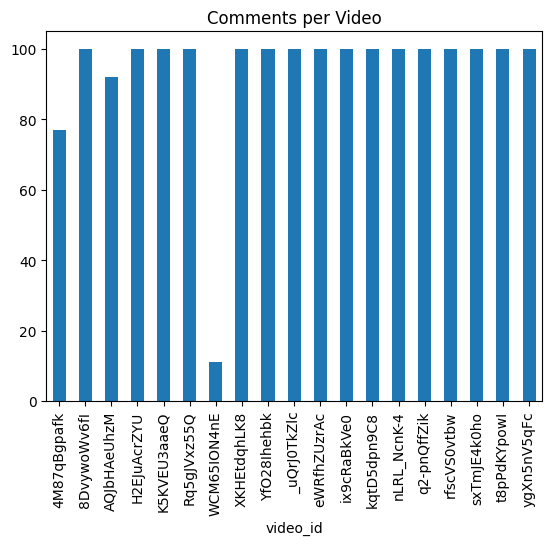

In [36]:
import matplotlib.pyplot as plt

comments_df.groupby("video_id").size().plot(kind="bar")
plt.title("Comments per Video")
plt.show()

PHASE 2 — Cleaning Validation

Before vs After Length

In [41]:
comments_df["original_len"] = comments_df["comment_text"].astype(str).apply(len)
comments_df["clean_comment"] = comments_df["clean_comment"].fillna("").astype(str)

comments_df["original_len"] = comments_df["comment_text"].fillna("").astype(str).apply(len)
comments_df["clean_len"] = comments_df["clean_comment"].apply(len)

print(comments_df[["original_len","clean_len"]].describe())

#print(comments_df[["original_len","clean_len"]].describe())

       original_len    clean_len
count   1780.000000  1780.000000
mean     123.258989   110.726966
std      406.592901   340.829782
min        0.000000     0.000000
25%       23.000000    21.000000
50%       49.500000    47.000000
75%      115.250000   108.250000
max     9714.000000  8652.000000


In [42]:
print("Empty cleaned comments:",
      (comments_df["clean_comment"].str.strip() == "").sum())

Empty cleaned comments: 27


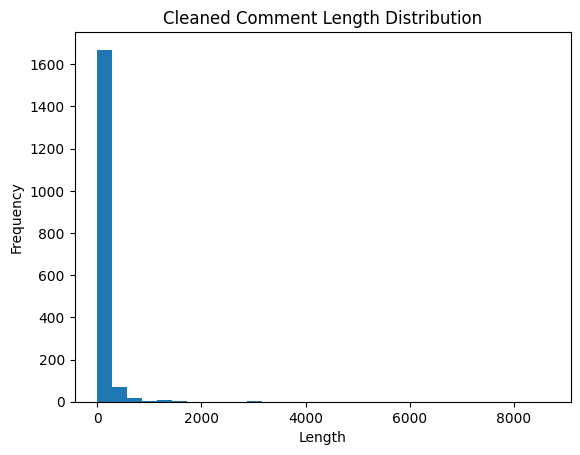

In [43]:
import matplotlib.pyplot as plt

plt.hist(comments_df["clean_len"], bins=30)
plt.title("Cleaned Comment Length Distribution")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()

PHASE 3 — Semantic Relevance Validation

Check Range

In [44]:
print(comments_df["relevance_score"].describe())

count    1780.000000
mean        0.755848
std         0.034917
min         0.640940
25%         0.730948
50%         0.752908
75%         0.780266
max         0.854659
Name: relevance_score, dtype: float64


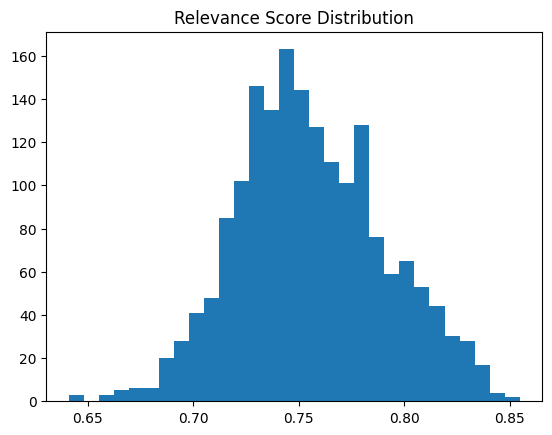

In [45]:
plt.hist(comments_df["relevance_score"], bins=30)
plt.title("Relevance Score Distribution")
plt.show()

PHASE 4 — Sentiment Validation

In [46]:
print(relevant_df["sentiment_score"].describe())

count    973.000000
mean       0.232759
std        0.552534
min       -0.945177
25%        0.000000
50%        0.000000
75%        0.880314
max        0.990728
Name: sentiment_score, dtype: float64


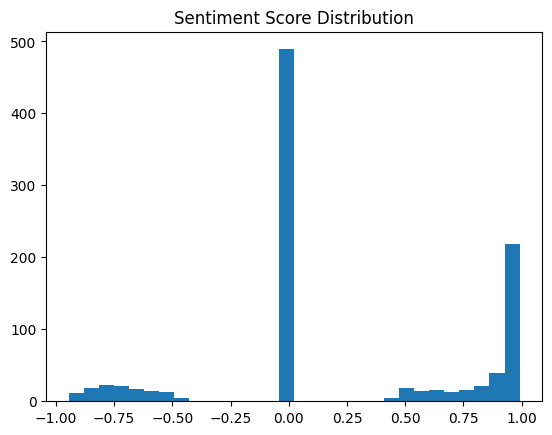

In [47]:
plt.hist(relevant_df["sentiment_score"], bins=30)
plt.title("Sentiment Score Distribution")
plt.show()

PHASE 5 — Emotional Engagement Validation

Check Bounds

In [48]:
print(relevant_df["emotion_weighted_score"].describe())

count    973.000000
mean       0.184263
std        0.432982
min       -0.737329
25%        0.000000
50%        0.000000
75%        0.693991
max        0.830293
Name: emotion_weighted_score, dtype: float64


emotional_variance

In [49]:
print(video_emotion_df["emotional_variance"].describe())

count    19.000000
mean      0.163785
std       0.060382
min       0.000000
25%       0.141456
50%       0.166105
75%       0.199372
max       0.247870
Name: emotional_variance, dtype: float64


PHASE 6 — Engagement Score Validation

check range

In [50]:
print(df["final_engagement_score"].describe())

count    19.000000
mean      0.430662
std       0.089360
min       0.200845
25%       0.398677
50%       0.422136
75%       0.508448
max       0.565743
Name: final_engagement_score, dtype: float64


Correlation with Likes

In [52]:
from scipy.stats import spearmanr
phase6_full = pd.read_csv("phase6_full.csv")
from scipy.stats import spearmanr

print(spearmanr(
    phase6_full["likes"],
    phase6_full["final_engagement_score"]
))

SignificanceResult(statistic=np.float64(0.368421052631579), pvalue=np.float64(0.12064548315260959))


Correlation with comment count

In [53]:
print(spearmanr(
    phase6_full["relevant_comment_count"],
    phase6_full["final_engagement_score"]
))

SignificanceResult(statistic=np.float64(0.16718073119063606), pvalue=np.float64(0.4939178936656562))


Correlation with emotional engagement

In [54]:
print(spearmanr(
    phase6_full["emotional_engagement"],
    phase6_full["final_engagement_score"]
))

SignificanceResult(statistic=np.float64(0.6070175438596491), pvalue=np.float64(0.00585043286767083))


In [55]:
from scipy.stats import spearmanr

metrics = [
    "likes",
    "relevant_comment_count",
    "emotional_engagement",
    "emotional_variance"
]

for m in metrics:
    corr = spearmanr(phase6_full[m], phase6_full["final_engagement_score"])
    print(f"{m} vs ES:", corr)

likes vs ES: SignificanceResult(statistic=np.float64(0.368421052631579), pvalue=np.float64(0.12064548315260959))
relevant_comment_count vs ES: SignificanceResult(statistic=np.float64(0.16718073119063606), pvalue=np.float64(0.4939178936656562))
emotional_engagement vs ES: SignificanceResult(statistic=np.float64(0.6070175438596491), pvalue=np.float64(0.00585043286767083))
emotional_variance vs ES: SignificanceResult(statistic=np.float64(0.1736842105263158), pvalue=np.float64(0.4770171488822207))


PHASE 7 — ITQS Validation

In [56]:
print(videos_df["ITQS"].describe())

count    20.000000
mean      0.634486
std       0.107776
min       0.388439
25%       0.616244
50%       0.652839
75%       0.716352
max       0.796285
Name: ITQS, dtype: float64


In [57]:
print(spearmanr(videos_df["semantic_alignment"], videos_df["ITQS"]))
print(spearmanr(videos_df["teaching_score"], videos_df["ITQS"]))

SignificanceResult(statistic=np.float64(0.3744360902255639), pvalue=np.float64(0.10384052952246073))
SignificanceResult(statistic=np.float64(0.6373740749087565), pvalue=np.float64(0.002504164291432392))


PHASE 8 — Hybrid Validation

check bounds

In [58]:
print(df["hybrid_score"].describe())

count    19.000000
mean      0.525558
std       0.074686
min       0.370325
25%       0.507914
50%       0.547525
75%       0.578994
max       0.605002
Name: hybrid_score, dtype: float64


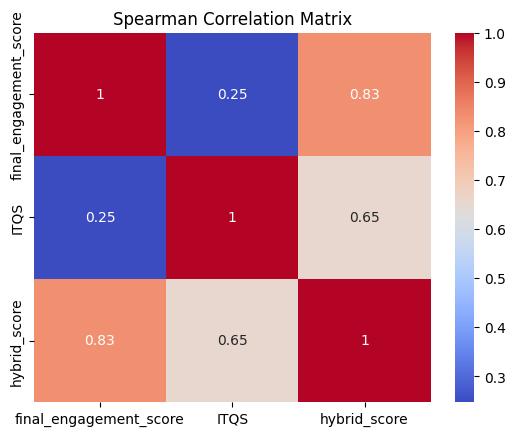

In [59]:
import seaborn as sns

corr = df[["final_engagement_score","ITQS","hybrid_score"]].corr(method="spearman")
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Spearman Correlation Matrix")
plt.show()

Top-K Overlap Analysis

1️⃣ Rank Stability (Bootstrap)

Resample comments → recompute ES → recompute hybrid → measure rank change.

That proves robustness.

2️⃣ Sensitivity Analysis of k

Plot α as function of comment count.

In [60]:
top_es = set(df.sort_values("final_engagement_score", ascending=False).head(5)["video_id"])
top_itqs = set(df.sort_values("ITQS", ascending=False).head(5)["video_id"])
top_hybrid = set(df.sort_values("hybrid_score", ascending=False).head(5)["video_id"])

print("ES-Hybrid overlap:", len(top_es & top_hybrid))
print("ITQS-Hybrid overlap:", len(top_itqs & top_hybrid))

ES-Hybrid overlap: 5
ITQS-Hybrid overlap: 1


testing

In [45]:
df_analysis = df_clean.copy()

df_analysis["rank_ES"] = df_analysis["final_engagement_score"].rank(ascending=False, method="dense")
df_analysis["rank_ITQS"] = df_analysis["ITQS"].rank(ascending=False, method="dense")
df_analysis["rank_Hybrid"] = df_analysis["hybrid_score"].rank(ascending=False, method="dense")

df_analysis.head()

,video_id,hybrid_score,final_rank,alpha,final_engagement_score,ITQS,relevant_comment_count,rank_ES,rank_ITQS,rank_Hybrid
0,_uQrJ0TkZlc,0.600232,1.0,0.562053,0.535189,0.683707,46,1.0,9.0,1.0
1,XKHEtdqhLK8,0.586706,2.0,0.536016,0.474750,0.716043,31,4.0,6.0,2.0
2,Rq5gJVxz55Q,0.573536,3.0,0.568423,0.456569,0.727590,51,5.0,4.0,3.0
3,rfscVS0vtbw,0.568638,4.0,0.523495,0.491053,0.653873,26,3.0,11.0,4.0
4,nLRL_NcnK-4,0.567975,5.0,0.523495,0.360160,0.796285,26,12.0,1.0,5.0


In [46]:
high_itqs = df_analysis.sort_values("rank_ITQS").head(5)
high_itqs

,video_id,hybrid_score,final_rank,alpha,final_engagement_score,ITQS,relevant_comment_count,rank_ES,rank_ITQS,rank_Hybrid
4,nLRL_NcnK-4,0.567975,5.0,0.523495,0.360160,0.796285,26,12.0,1.0,5.0
7,ix9cRaBkVe0,0.532399,8.0,0.551494,0.357644,0.747282,39,13.0,2.0,8.0
9,8DvywoWv6fI,0.523410,10.0,0.549790,0.345135,0.741116,38,15.0,3.0,10.0
2,Rq5gJVxz55Q,0.573536,3.0,0.568423,0.456569,0.727590,51,5.0,4.0,3.0
10,4M87qBgpafk,0.514095,11.0,0.548028,0.343555,0.720878,37,16.0,5.0,11.0


In [47]:
df_analysis["hybrid_vs_ES_shift"] = df_analysis["rank_ES"] - df_analysis["rank_Hybrid"]
df_analysis["hybrid_vs_ITQS_shift"] = df_analysis["rank_ITQS"] - df_analysis["rank_Hybrid"]

df_analysis.sort_values("hybrid_vs_ES_shift", ascending=False).head()

,video_id,hybrid_score,final_rank,alpha,final_engagement_score,ITQS,relevant_comment_count,rank_ES,rank_ITQS,rank_Hybrid,hybrid_vs_ES_shift,hybrid_vs_ITQS_shift
14,WCM65ION4nE,0.471167,15.0,0.268045,0.201138,0.570053,2,24.0,17.0,15.0,9.0,2.0
4,nLRL_NcnK-4,0.567975,5.0,0.523495,0.360160,0.796285,26,12.0,1.0,5.0,7.0,-4.0
9,8DvywoWv6fI,0.523410,10.0,0.549790,0.345135,0.741116,38,15.0,3.0,10.0,5.0,-7.0
7,ix9cRaBkVe0,0.532399,8.0,0.551494,0.357644,0.747282,39,13.0,2.0,8.0,5.0,-6.0
16,eWRfhZUzrAc,0.437369,17.0,0.560674,0.269215,0.651971,45,22.0,12.0,17.0,5.0,-5.0


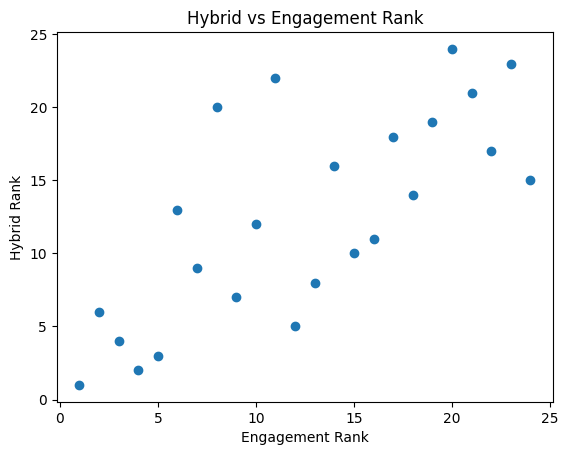

In [48]:
import matplotlib.pyplot as plt

plt.scatter(df_analysis["rank_ES"], df_analysis["rank_Hybrid"])
plt.xlabel("Engagement Rank")
plt.ylabel("Hybrid Rank")
plt.title("Hybrid vs Engagement Rank")
plt.show()

In [49]:
improved = (df_analysis["hybrid_vs_ES_shift"] > 0).sum()
print("Videos improved over ES ranking:", improved)

Videos improved over ES ranking: 10


In [50]:
df_analysis["hybrid_vs_ES_shift"].mean()

np.float64(0.0)